# December preprint: diabetes x food access
## Design (changed Oct 25): Level 1 = California vs Michigan (all tracts, urban/rural split). Level 2 spotlight = Metro Detroit vs Metro Los Angeles (official Census metro areas).
**Run top to bottom after the files are in `data/raw/`.**

| File | Full name | Where | Saved as |
|---|---|---|---|
| CDC PLACES 2025 | Population Level Analysis and Community Estimates, census tract, GIS-friendly CSV | https://catalog.data.gov/dataset/places-census-tract-data-gis-friendly-format-2025-release-4c3af | `data/raw/places_tract_2025.csv` ✅ |
| USDA SRAM 2025 | **SNAP-authorized Retailer Access Map**: ALL stores that accept SNAP food benefits (supermarkets, small groceries, convenience and dollar stores) | https://www.ers.usda.gov/data-products/food-access-research-atlas/download-the-data | `data/raw/2025-sram-fara-data/` (3 CSVs) ✅ |
| USDA LRAM 2019 | **Large Retailer Access Map**: ONLY supermarkets, supercenters and large grocery stores (formerly "Food Access Research Atlas") | same page | `data/raw/2019_Food_Access_Research_Atlas_Data/` ✅ |
| Census CBSA list, July 2023 | Core-Based Statistical Area (official metro area) delineation file | https://www.census.gov/geographies/reference-files/time-series/demo/metro-micro/delineation-files.html | `data/raw/cbsa_list1_2023.xlsx` |
| Census tract relationship file | Links 2010 tracts to 2020 tracts (needed only for LRAM) | https://www.census.gov/geographies/reference-files/time-series/geo/relationship-files.2020.html | `data/raw/tract_rel_2020_2010.txt` |

Steps marked **CHECK** need you to confirm a column name.


In [2]:
import pandas as pd, numpy as np
from pathlib import Path
RAW, CLEAN, FIG = Path('../data/raw'), Path('../data/clean'), Path('../figures')
STATES = {'06':'California', '26':'Michigan'}
# Official metro areas (CBSA). Fallback county lists below; the cell under them checks against the Census file.
METROS = {
    'Metro Detroit':     {'cbsa':'19820', 'counties':['26163','26125','26099','26093','26147','26087']},  # Wayne, Oakland, Macomb, Livingston, St. Clair, Lapeer
    'Metro Los Angeles': {'cbsa':'31080', 'counties':['06037','06059']},                                   # Los Angeles, Orange
}
try:   # CHECK: verify county lists against the official delineation file
    cb = pd.read_excel(RAW/'list1_2023.xlsx', header=2, dtype=str)
    cb['fips'] = cb['FIPS State Code'] + cb['FIPS County Code']
    for name, m in METROS.items():
        official = sorted(cb.loc[cb['CBSA Code']==m['cbsa'], 'fips'])
        print(name, 'official:', official, '| matches fallback:', official==sorted(m['counties']))
        m['counties'] = official
except FileNotFoundError:
    print('CBSA file not downloaded yet: using fallback county lists (VERIFY)')
COUNTY2METRO = {c:name for name,m in METROS.items() for c in m['counties']}


Metro Detroit official: ['26087', '26093', '26099', '26125', '26147', '26163'] | matches fallback: True
Metro Los Angeles official: ['06037', '06059'] | matches fallback: True


## 1. CDC PLACES 2025 (tracts)
Keep GEOIDs as TEXT so California's leading 0 isn't lost.

In [3]:
places = pd.read_csv(RAW/'places_tract_2025.csv', dtype={'TractFIPS':str,'CountyFIPS':str})
print(places.columns.tolist()[:40])          # CHECK: is it DIABETES_CrudePrev (crude) or age-adjusted?
places['GEOID'] = places['TractFIPS'].str.zfill(11)
places['county'] = places['GEOID'].str[:5]
places = places[places['GEOID'].str[:2].isin(STATES)].copy()       # ALL tracts in CA + MI
places['state'] = places['GEOID'].str[:2].map(STATES)
places['metro'] = places['county'].map(COUNTY2METRO).fillna('Rest of state')
# 95% CI is a text column like '(9.1, 11.2)': split into low/high
ci = places['DIABETES_Crude95CI'].str.strip('() ').str.split(',', expand=True).astype(float)   # CHECK name
places['diab'] = places['DIABETES_CrudePrev']; places['diab_lo'] = ci[0]; places['diab_hi'] = ci[1]
places['adults'] = pd.to_numeric(places['TotalPop18plus'].astype(str).str.replace(',', ''), errors='coerce')   # FIXED Oct 28: numbers stored as text with commas, e.g. '1,370'                                                     # CHECK name
places = places[['GEOID','county','state','metro','adults','diab','diab_lo','diab_hi']]
print(pd.crosstab(places['state'], places['metro']))


['StateAbbr', 'StateDesc', 'CountyName', 'CountyFIPS', 'TractFIPS', 'TotalPopulation', 'TotalPop18plus', 'ACCESS2_CrudePrev', 'ACCESS2_Crude95CI', 'ARTHRITIS_CrudePrev', 'ARTHRITIS_Crude95CI', 'BINGE_CrudePrev', 'BINGE_Crude95CI', 'BPHIGH_CrudePrev', 'BPHIGH_Crude95CI', 'BPMED_CrudePrev', 'BPMED_Crude95CI', 'CANCER_CrudePrev', 'CANCER_Crude95CI', 'CASTHMA_CrudePrev', 'CASTHMA_Crude95CI', 'CHD_CrudePrev', 'CHD_Crude95CI', 'CHECKUP_CrudePrev', 'CHECKUP_Crude95CI', 'CHOLSCREEN_CrudePrev', 'CHOLSCREEN_Crude95CI', 'COLON_SCREEN_CrudePrev', 'COLON_SCREEN_Crude95CI', 'COPD_CrudePrev', 'COPD_Crude95CI', 'CSMOKING_CrudePrev', 'CSMOKING_Crude95CI', 'DENTAL_CrudePrev', 'DENTAL_Crude95CI', 'DEPRESSION_CrudePrev', 'DEPRESSION_Crude95CI', 'DIABETES_CrudePrev', 'DIABETES_Crude95CI', 'GHLTH_CrudePrev']
metro       Metro Detroit  Metro Los Angeles  Rest of state
state                                                      
California              0               3086           5984
Michigan             1

## 2. USDA SRAM 2025 = SNAP-authorized Retailer Access Map (ALL stores that accept SNAP food benefits: supermarkets, small groceries, convenience and dollar stores) (primary food-access measure; 2020 tracts)
Column names checked against the SRAM Variable Lookup files (Oct 28). Files are latin-1 encoded (county names like Doña Ana).

In [4]:
# SRAM 2025 comes as 3 CSV files (checked Oct 28): general tract info, straight-line distance, driving distance.
SRAM_DIR = RAW/'2025-sram-fara-data'
def read_sram(name, cols):
    x = pd.read_csv(SRAM_DIR/name, dtype={'CensusTract20':str}, encoding='latin-1', usecols=['CensusTract20']+cols)
    x['GEOID'] = x['CensusTract20'].str.zfill(11)          # tract IDs lost their leading 0
    return x.drop(columns='CensusTract20')
gen = read_sram('SRAM General Tract Characteristics Data.csv',
                ['Urban','POP2020','OHU2020','TractSeniors','TractHUNV','LowIncomeTracts'])
sl  = read_sram('SRAM Straight Line Distance Data.csv',
                ['SD_SRAM_LILATracts_1And10','SD_SRAM_LILATracts_halfAnd10','SD_SRAM_LILATracts_Vehicle'])
dd  = read_sram('SRAM Driving Distance Data.csv', ['DD_SRAM_LILATracts_1And10'])
sram = gen.merge(sl, on='GEOID').merge(dd, on='GEOID').rename(columns={
    'Urban':'urban', 'LowIncomeTracts':'low_income',
    'SD_SRAM_LILATracts_1And10':'lila_1_10',        # PRIMARY: 1 mi urban / 10 mi rural, straight line
    'SD_SRAM_LILATracts_halfAnd10':'lila_half',      # sensitivity: 1/2 mi urban
    'SD_SRAM_LILATracts_Vehicle':'lila_vehicle',     # sensitivity: low income + many households without a car
    'DD_SRAM_LILATracts_1And10':'lila_drive_1_10'})  # sensitivity: driving distance
sram['pct_no_vehicle'] = (100*sram['TractHUNV']/sram['OHU2020']).clip(upper=100)   # a few tracts >100%: counts come from different sources; cap at 100 (note in Methods)
sram['pct_65plus']     = 100*sram['TractSeniors']/sram['POP2020']
sram = sram[sram['GEOID'].str[:2].isin(STATES)]
print(sram.groupby(sram['GEOID'].str[:2].map(STATES))[['lila_1_10','lila_half','lila_vehicle','lila_drive_1_10']].sum())


            lila_1_10  lila_half  lila_vehicle  lila_drive_1_10
GEOID                                                          
California      155.0      802.0          64.0            426.0
Michigan         54.0      263.0          67.0            167.0


## 3. Join + quality checks

In [5]:
df = places.merge(sram, on='GEOID', how='left', indicator=True)
print(df['_merge'].value_counts())          # expect almost all 'both'
n0 = len(df)
n_small = (df['adults']<50).sum(); df = df[df['adults']>=50]
n_miss = df[['diab','lila_1_10']].isna().any(axis=1).sum(); df = df.dropna(subset=['diab','lila_1_10']).drop(columns='_merge')
print(f'FLOW (STROBE 13): start {n0} -> dropped <50 adults {n_small} -> dropped missing {n_miss} -> analysed {len(df)}')
df['area'] = np.where(df['urban']==1, 'Urban', 'Rural')
df.to_csv(CLEAN/'tracts_ca_mi.csv', index=False)


_merge
both          11974
left_only         0
right_only        0
Name: count, dtype: int64
FLOW (STROBE 13): start 11974 -> dropped <50 adults 0 -> dropped missing 0 -> analysed 11974


## 4. Double burden = top-quartile diabetes (within STATE) AND low income/low access
Same rule for every tract in a state, so metro and urban/rural results are comparable.

In [6]:
df['p75'] = df.groupby('state')['diab'].transform(lambda s: s.quantile(0.75))
df['high_diab'] = df['diab'] >= df['p75']
df['double'] = df['high_diab'] & (df['lila_1_10']==1)
for c in ['diab','diab_lo','diab_hi']:
    df['n_'+c] = df[c]/100*df['adults']          # estimated adults with diabetes (point, low, high)
def summarise(by):
    s = df.groupby(by).agg(tracts=('GEOID','count'), adults=('adults','sum'),
                           mean_diab=('diab','mean'), lila_tracts=('lila_1_10','sum'), double_tracts=('double','sum'))
    dd = df[df['double']].groupby(by)[['n_diab','n_diab_lo','n_diab_hi']].sum().round(0)
    s = s.join(dd).fillna({'n_diab':0,'n_diab_lo':0,'n_diab_hi':0}); s['pct_tracts_double'] = (100*s['double_tracts']/s['tracts']).round(1)
    s['mean_diab'] = s['mean_diab'].round(1); s['lila_tracts'] = s['lila_tracts'].astype(int)
    return s.astype({'n_diab':int,'n_diab_lo':int,'n_diab_hi':int})
print('LEVEL 1a: state vs state');               display(summarise('state'))
print('LEVEL 1b: urban vs urban, rural vs rural'); display(summarise(['state','area']))
print('LEVEL 2: metro spotlight');                display(summarise(['state','metro']))


LEVEL 1a: state vs state


,tracts,adults,mean_diab,lila_tracts,double_tracts,n_diab,n_diab_lo,n_diab_hi,pct_tracts_double
state,,,,,,,,,
California,9070,30826739,11.6,154,71,35316,30958,40005,0.8
Michigan,2904,7914297,12.6,52,19,6914,6046,7840,0.7


LEVEL 1b: urban vs urban, rural vs rural


tracts    adults  mean_diab  lila_tracts  double_tracts  \
state      area                                                             
California Rural     838   2429582       12.4           14              9   
           Urban    8232  28397157       11.5          140             62   
Michigan   Rural     861   2353951       12.4            6              5   
           Urban    2043   5560346       12.6           46             14   

                  n_diab  n_diab_lo  n_diab_hi  pct_tracts_double  
state      area                                                    
California Rural    2805       2443       3212                1.1  
           Urban   32511      28515      36794                0.8  
Michigan   Rural    1700       1472       1943                0.6  
           Urban    5214       4574       5897                0.7

LEVEL 2: metro spotlight


tracts    adults  mean_diab  lila_tracts  \
state      metro                                                         
California Metro Los Angeles    3086  10479239       12.0            7   
           Rest of state        5984  20347500       11.4          147   
Michigan   Metro Detroit        1297   3440827       12.8            2   
           Rest of state        1607   4473470       12.4           50   

                              double_tracts  n_diab  n_diab_lo  n_diab_hi  \
state      metro                                                            
California Metro Los Angeles              1      20         19         22   
           Rest of state                 70   35296      30939      39983   
Michigan   Metro Detroit                  0       0          0          0   
           Rest of state                 19    6914       6046       7840   

                              pct_tracts_double  
state      metro                                 
California Metro Los Angeles                0.0  
           Rest of state                    1.2  
Michigan   Metro Detroit                    0.0  
           Rest of state                    1.2

## 5. Concentration: how many tracts hold half of double-burden adults? (by state and metro)

In [7]:
for key, g in df[df['double']].groupby(['state','metro']):
    s = g.sort_values('n_diab', ascending=False)['n_diab'].cumsum()
    print(key, (s < s.iloc[-1]/2).sum()+1, 'of', len(g), 'double-burden tracts hold half')


('California', 'Metro Los Angeles') 1 of 1 double-burden tracts hold half
('California', 'Rest of state') 24 of 70 double-burden tracts hold half
('Michigan', 'Rest of state') 8 of 19 double-burden tracts hold half


## 6. Fair contrasts (headline #3): share of adults living in double-burden tracts

In [8]:
def share(g): return g.loc[g['double'],'adults'].sum()/g['adults'].sum()
st  = df.groupby('state').apply(share)
urb = df[df['area']=='Urban'].groupby('state').apply(share)
met = df[df['metro']!='Rest of state'].groupby('metro').apply(share)
print('State  MI/CA ratio:', round(st['Michigan']/st['California'],2), st.round(3).to_dict())
print('Urban  MI/CA ratio:', round(urb['Michigan']/urb['California'],2), urb.round(3).to_dict())
print('Metro  Detroit/LA ratio:', round(met['Metro Detroit']/met['Metro Los Angeles'],2), met.round(3).to_dict())


State  MI/CA ratio: 0.71 {'California': 0.007, 'Michigan': 0.005}
Urban  MI/CA ratio: 0.76 {'California': 0.007, 'Michigan': 0.006}
Metro  Detroit/LA ratio: 0.0 {'Metro Detroit': 0.0, 'Metro Los Angeles': 0.0}


## 7. Descriptive model (association only; PLACES already contains demographics + poverty)
Add ACS poverty and % 65+ after downloading ACS (data.census.gov) or via the Census API.

In [9]:
# 7a. Main model (association only). Changed Oct 28: tidy table instead of m.summary(), which crashed the kernel on Windows.
import statsmodels.formula.api as smf
def tidy(model):
    t = pd.DataFrame({'coef': model.params, 'ci_low': model.conf_int()[0], 'ci_high': model.conf_int()[1], 'p_value': model.pvalues})
    return t.round(3)
m = smf.ols('diab ~ lila_1_10 + pct_no_vehicle + C(area) + C(state)', data=df).fit(cov_type='HC1')
print('Tracts used:', int(m.nobs), '| R-squared:', round(m.rsquared, 3))
display(tidy(m))


Tracts used: 11959 | R-squared: 0.125


,coef,ci_low,ci_high,p_value
Intercept,11.558,11.407,11.709,0.0
C(area)[T.Urban],-0.976,-1.121,-0.830,0.0
C(state)[T.Michigan],0.688,0.531,0.844,0.0
lila_1_10,1.497,0.960,2.035,0.0
pct_no_vehicle,0.126,0.111,0.141,0.0


In [10]:
# 7b-i. Does the food-desert link differ by state? (interaction; STROBE 12b)
m2 = smf.ols('diab ~ lila_1_10*C(state) + pct_no_vehicle + C(area)', data=df).fit(cov_type='HC1')
display(tidy(m2))
# 7b-ii. Age check: add % aged 65+ (crude rates are not age-adjusted)
m3 = smf.ols('diab ~ lila_1_10 + pct_no_vehicle + pct_65plus + C(area) + C(state)', data=df).fit(cov_type='HC1')
display(tidy(m3))


,coef,ci_low,ci_high,p_value
Intercept,11.549,11.398,11.700,0.00
C(state)[T.Michigan],0.707,0.550,0.864,0.00
C(area)[T.Urban],-0.971,-1.117,-0.825,0.00
lila_1_10,1.763,1.173,2.354,0.00
lila_1_10:C(state)[T.Michigan],-1.051,-2.378,0.276,0.12
pct_no_vehicle,0.126,0.111,0.141,0.00


,coef,ci_low,ci_high,p_value
Intercept,10.340,10.089,10.592,0.0
C(area)[T.Urban],-0.677,-0.822,-0.531,0.0
C(state)[T.Michigan],0.606,0.450,0.762,0.0
lila_1_10,1.389,0.880,1.899,0.0
pct_no_vehicle,0.129,0.115,0.144,0.0
pct_65plus,0.058,0.049,0.067,0.0


## 7b. Spatial check (Moran's I on residuals; spatial lag model if needed)
Neighbors look alike? If the leftover errors cluster on the map, re-run as a spatial lag model.

In [11]:
# 7b. Spatial check: are the leftover errors (residuals) clustered on the map? (Moran's I)
import geopandas as gpd, libpysal, esda, warnings
from spreg import GM_Lag
warnings.filterwarnings('ignore')
tr = pd.concat([gpd.read_file(RAW/'cb_2020_06_tract_500k.zip'), gpd.read_file(RAW/'cb_2020_26_tract_500k.zip')])
g = tr[['GEOID','geometry']].merge(df.loc[m.resid.index].assign(resid=m.resid), on='GEOID')
w = libpysal.weights.Queen.from_dataframe(g, use_index=False); w.transform = 'r'
mi = esda.Moran(g['resid'], w)
print("Moran's I =", round(mi.I, 3), '| p =', mi.p_sim, '| tracts:', len(g))
if mi.p_sim < 0.05:   # residuals clustered -> spatial lag model (fast GM version, robust errors)
    X = pd.get_dummies(g[['lila_1_10','pct_no_vehicle','area','state']], drop_first=True).astype(float)
    lag = GM_Lag(g[['diab']].values, X.values, w=w, name_y='diab', name_x=list(X.columns), robust='white')
    print(pd.DataFrame({'coef': lag.betas.flatten(), 'se': lag.std_err}, index=['Intercept']+list(X.columns)+['W_diab (neighbors)']).round(3))


('WARNING: ', 9176, ' is an island (no neighbors)')
Moran's I = 0.642 | p = 0.001 | tracts: 11959
GM_Lag
                     coef     se
Intercept           7.979  0.805
lila_1_10           1.220  0.249
pct_no_vehicle      0.104  0.009
area_Urban         -0.753  0.085
state_Michigan      0.465  0.080
W_diab (neighbors)  0.304  0.069


## 8. Sensitivity: half-mile definition + LRAM 2019 = Large Retailer Access Map (ONLY supermarkets, supercenters and large grocery stores)
LRAM uses 2010 tracts: crosswalk with the Census relationship file (population or area weights) before joining. The SRAM vs LRAM comparison = how many high-diabetes tracts are food deserts by supermarket-only but NOT by any-SNAP-store.

In [12]:
# Pre-specified extra checks (decided Oct 28, before outcome results): same "top 25% diabetes" rule,
# different food-desert rules. Shows how many double-burden tracts each rule finds.
rules = {'lila_1_10':'MAIN: 1 mi city / 10 mi rural (straight line)',
         'lila_half':'Check 1: 1/2 mi city',
         'lila_drive_1_10':'Check 2: driving distance 1 mi / 10 mi',
         'lila_vehicle':'Check 3: low income + many households without a car'}
rows = []
for col, label in rules.items():
    d = df['high_diab'] & (df[col]==1)
    for (st, me), g in df.assign(d=d).groupby(['state','metro']):
        rows.append({'rule':label, 'state':st, 'metro':me, 'food_desert_tracts':int(g[col].sum()),
                     'double_tracts':int(g['d'].sum()),
                     'adults_with_diabetes':int((g.loc[g['d'],'diab']/100*g.loc[g['d'],'adults']).sum())})
check = pd.DataFrame(rows)
display(check.pivot_table(index=['state','metro'], columns='rule', values='double_tracts', aggfunc='sum'))
display(check.pivot_table(index=['state','metro'], columns='rule', values='adults_with_diabetes', aggfunc='sum'))
# LRAM 2019 (Large Retailer Access Map, supermarkets only): TODO next session, needs 2010->2020 tract crosswalk


rule                          Check 1: 1/2 mi city  \
state      metro                                     
California Metro Los Angeles                    42   
           Rest of state                       275   
Michigan   Metro Detroit                        18   
           Rest of state                        76   

rule                          Check 2: driving distance 1 mi / 10 mi  \
state      metro                                                       
California Metro Los Angeles                                      13   
           Rest of state                                         176   
Michigan   Metro Detroit                                           3   
           Rest of state                                          56   

rule                          Check 3: low income + many households without a car  \
state      metro                                                                    
California Metro Los Angeles                                                  6     
           Rest of state                                                     33     
Michigan   Metro Detroit                                                      2     
           Rest of state                                                     28     

rule                          MAIN: 1 mi city / 10 mi rural (straight line)  
state      metro                                                             
California Metro Los Angeles                                              1  
           Rest of state                                                 70  
Michigan   Metro Detroit                                                  0  
           Rest of state                                                 19

rule                          Check 1: 1/2 mi city  \
state      metro                                     
California Metro Los Angeles                 23941   
           Rest of state                    140350   
Michigan   Metro Detroit                      6581   
           Rest of state                     30394   

rule                          Check 2: driving distance 1 mi / 10 mi  \
state      metro                                                       
California Metro Los Angeles                                    6926   
           Rest of state                                       86887   
Michigan   Metro Detroit                                        1483   
           Rest of state                                       21585   

rule                          Check 3: low income + many households without a car  \
state      metro                                                                    
California Metro Los Angeles                                               3873     
           Rest of state                                                  19821     
Michigan   Metro Detroit                                                    898     
           Rest of state                                                  12883     

rule                          MAIN: 1 mi city / 10 mi rural (straight line)  
state      metro                                                             
California Metro Los Angeles                                             20  
           Rest of state                                              35295  
Michigan   Metro Detroit                                                  0  
           Rest of state                                               6913

## 8b. AIM 2: Large Retailer Access Map (LRAM 2019, big stores only) vs SNAP-authorized Retailer Access Map (SRAM 2025, all SNAP stores)
Where do convenience and dollar stores make a neighborhood look like it has food access? ('HIDDEN' tracts)

In [13]:
# 8b. AIM 2: LRAM 2019 (Large Retailer Access Map = big stores only) vs SRAM 2025 (all SNAP stores)
# LRAM uses 2010 tracts -> move its food-desert label onto 2020 tracts with the Census relationship file.
# Weight = share of each 2020 tract's LAND AREA that came from each 2010 tract (area weighting; limitation: not population-weighted).
rel = pd.read_csv(RAW/'tab20_tract20_tract10_natl.txt', sep='|', encoding='utf-8-sig',
                  dtype={'GEOID_TRACT_20':str,'GEOID_TRACT_10':str},
                  usecols=['GEOID_TRACT_20','GEOID_TRACT_10','AREALAND_TRACT_20','AREALAND_PART'])
rel = rel[rel['GEOID_TRACT_20'].str[:2].isin(STATES) & (rel['AREALAND_TRACT_20'] > 0)]
rel['w'] = rel['AREALAND_PART'] / rel['AREALAND_TRACT_20']
lram = pd.read_csv(RAW/'2019_Food_Access_Research_Atlas_Data'/'Food Access Research Atlas.csv', encoding='latin-1',
                   dtype={'CensusTract':str}, usecols=['CensusTract','LILATracts_1And10','LILATracts_halfAnd10'])
lram['GEOID_TRACT_10'] = lram['CensusTract'].str.zfill(11)
x = rel.merge(lram, on='GEOID_TRACT_10', how='left')
x['w1'] = x['w']*x['LILATracts_1And10']; x['wh'] = x['w']*x['LILATracts_halfAnd10']
cw = x.groupby('GEOID_TRACT_20').agg(lram_share=('w1','sum'), lram_share_half=('wh','sum'), wsum=('w','sum')).reset_index()
cw['lram_1_10'] = (cw['lram_share']/cw['wsum'] >= 0.5).astype(int)        # 2020 tract counts as LRAM food desert if >=50% of its land was
cw['lram_half'] = (cw['lram_share_half']/cw['wsum'] >= 0.5).astype(int)
df = df.drop(columns=[c for c in ['lram_1_10','lram_half'] if c in df]).merge(
        cw[['GEOID_TRACT_20','lram_1_10','lram_half']].rename(columns={'GEOID_TRACT_20':'GEOID'}), on='GEOID', how='left')
print('2020 tracts with an LRAM label:', df['lram_1_10'].notna().sum(), 'of', len(df))

def compare(d):
    s, l = d['lila_1_10']==1, d['lram_1_10']==1
    return pd.Series({'tracts': len(d),
        'LRAM food desert (big stores only)': int(l.sum()),
        'SRAM food desert (any SNAP store)': int(s.sum()),
        'both': int((l & s).sum()),
        'HIDDEN: LRAM yes, SRAM no': int((l & ~s).sum()),
        'reverse: SRAM yes, LRAM no': int((s & ~l).sum())})
print('ALL tracts (1 mile city / 10 miles rural):')
display(df.groupby(['state','metro']).apply(compare, include_groups=False))
print('HIGH-DIABETES tracts only (top 25% in state):')
display(df[df['high_diab']].groupby(['state','metro']).apply(compare, include_groups=False))
hid = df[df['high_diab'] & (df['lram_1_10']==1) & (df['lila_1_10']==0)]
print('Adults with diabetes in HIDDEN high-diabetes tracts:')
display((hid['diab']/100*hid['adults']).groupby([hid['state'], hid['metro']]).sum().round(0))


2020 tracts with an LRAM label: 11974 of 11974
ALL tracts (1 mile city / 10 miles rural):


tracts  LRAM food desert (big stores only)  \
state      metro                                                           
California Metro Los Angeles    3086                                  65   
           Rest of state        5984                                 583   
Michigan   Metro Detroit        1297                                  97   
           Rest of state        1607                                 255   

                              SRAM food desert (any SNAP store)  both  \
state      metro                                                        
California Metro Los Angeles                                  7     5   
           Rest of state                                    147    76   
Michigan   Metro Detroit                                      2     0   
           Rest of state                                     50    23   

                              HIDDEN: LRAM yes, SRAM no  \
state      metro                                          
California Metro Los Angeles                         60   
           Rest of state                            507   
Michigan   Metro Detroit                             97   
           Rest of state                            232   

                              reverse: SRAM yes, LRAM no  
state      metro                                          
California Metro Los Angeles                           2  
           Rest of state                              71  
Michigan   Metro Detroit                               2  
           Rest of state                              27

HIGH-DIABETES tracts only (top 25% in state):


tracts  LRAM food desert (big stores only)  \
state      metro                                                           
California Metro Los Angeles    1000                                  31   
           Rest of state        1288                                 266   
Michigan   Metro Detroit         358                                  51   
           Rest of state         387                                 120   

                              SRAM food desert (any SNAP store)  both  \
state      metro                                                        
California Metro Los Angeles                                  1     1   
           Rest of state                                     70    41   
Michigan   Metro Detroit                                      0     0   
           Rest of state                                     19    11   

                              HIDDEN: LRAM yes, SRAM no  \
state      metro                                          
California Metro Los Angeles                         30   
           Rest of state                            225   
Michigan   Metro Detroit                             51   
           Rest of state                            109   

                              reverse: SRAM yes, LRAM no  
state      metro                                          
California Metro Los Angeles                           0  
           Rest of state                              29  
Michigan   Metro Detroit                               0  
           Rest of state                               8

Adults with diabetes in HIDDEN high-diabetes tracts:


state       metro            
California  Metro Los Angeles     15633.0
            Rest of state        101953.0
Michigan    Metro Detroit         19504.0
            Rest of state         37939.0
dtype: float64

## 9. Maps (Figure 1)
Uses the Census 2020 cartographic boundary files (cb_2020_06 = California, cb_2020_26 = Michigan) in data/raw.

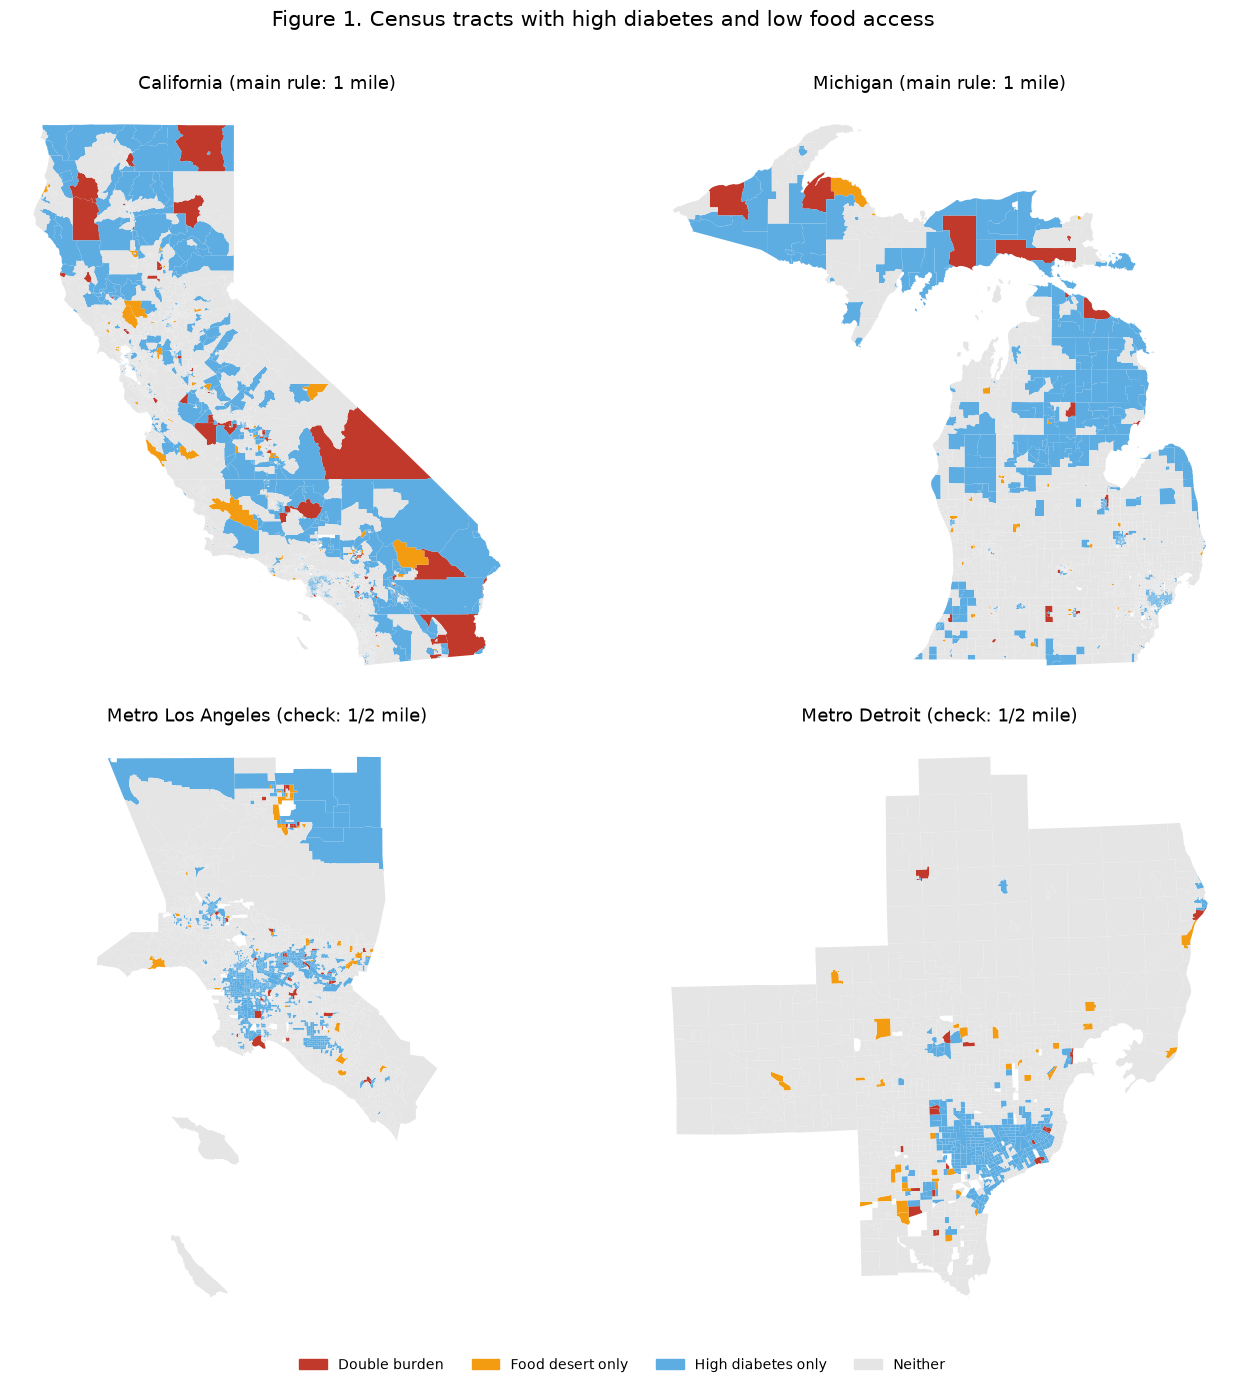

In [14]:
# 9. Figure 1: maps. Colors: red = double burden, orange = food desert only, blue = high diabetes only, grey = neither
import matplotlib.pyplot as plt
mp = tr[['GEOID','geometry']].merge(df, on='GEOID')
def cat(d, col):
    return np.select([d['high_diab'] & (d[col]==1), d[col]==1, d['high_diab']], ['Double burden','Food desert only','High diabetes only'], 'Neither')
colors = {'Double burden':'#c0392b','Food desert only':'#f39c12','High diabetes only':'#5dade2','Neither':'#e5e5e5'}
panels = [('California (main rule: 1 mile)', mp[mp.state=='California'], 'lila_1_10'),
          ('Michigan (main rule: 1 mile)',   mp[mp.state=='Michigan'],   'lila_1_10'),
          ('Metro Los Angeles (check: 1/2 mile)', mp[mp.metro=='Metro Los Angeles'], 'lila_half'),
          ('Metro Detroit (check: 1/2 mile)',     mp[mp.metro=='Metro Detroit'],     'lila_half')]
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for ax, (title, d, col) in zip(axes.flat, panels):
    d = d.assign(cat=cat(d, col))
    for k, colr in colors.items():
        sub = d[d['cat']==k]
        if len(sub): sub.plot(ax=ax, color=colr, linewidth=0)
    ax.set_title(title, fontsize=13); ax.set_axis_off()
handles = [plt.Rectangle((0,0),1,1,color=v) for v in colors.values()]
fig.legend(handles, colors.keys(), loc='lower center', ncol=4, frameon=False)
fig.suptitle('Figure 1. Census tracts with high diabetes and low food access', fontsize=15)
plt.tight_layout(rect=[0,0.03,1,0.97])
FIG.mkdir(exist_ok=True); plt.savefig(FIG/'fig1_double_burden_maps.png', dpi=200)
plt.show()


## 10. Figure 2 (aim 2): high-diabetes tracts hidden by smaller stores
Red = HIDDEN (no large grocery store nearby on LRAM 2019, but 'has access' on SRAM 2025). Dark = food desert on both maps. Light blue = other high-diabetes tracts. Grey = not high diabetes.

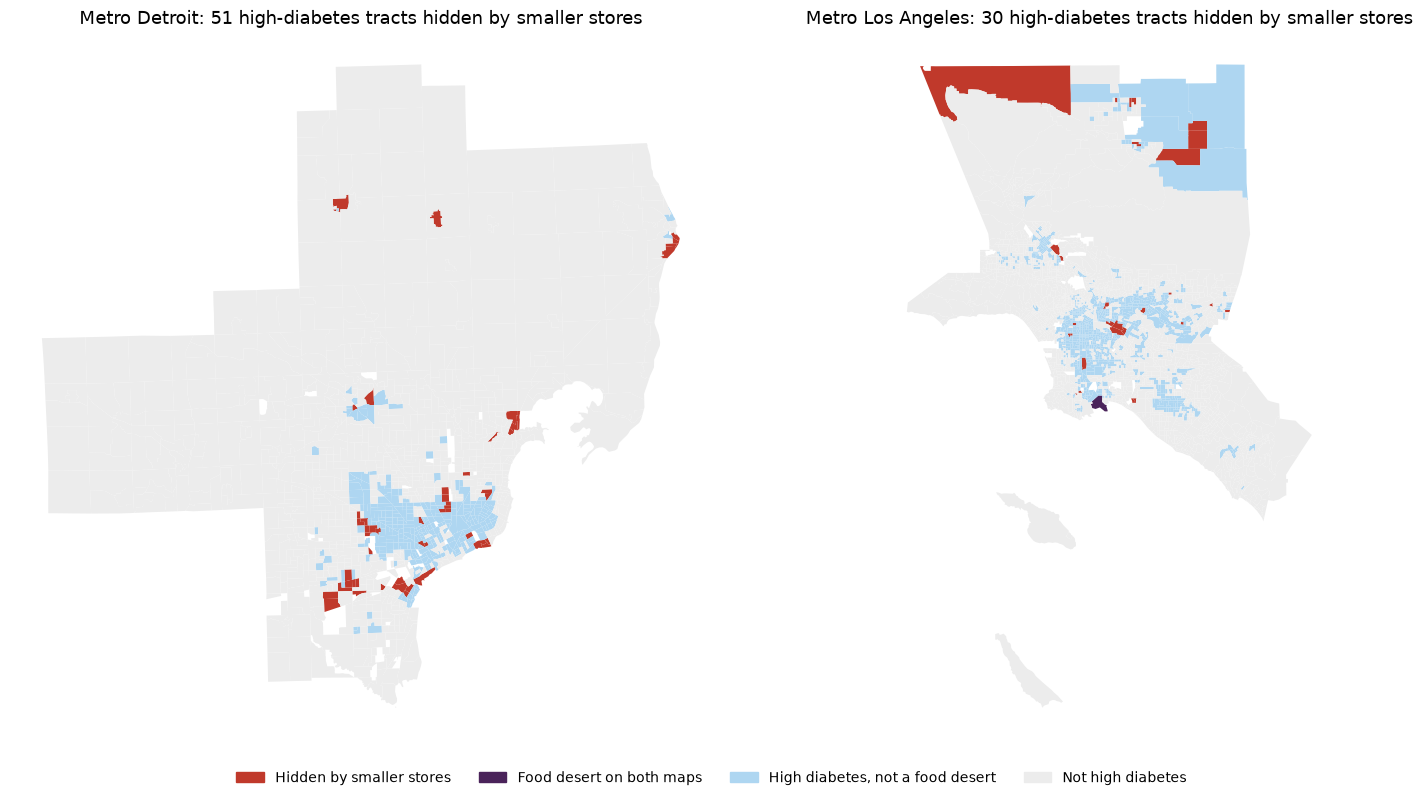

In [15]:
mp2 = tr[['GEOID','geometry']].merge(df, on='GEOID')
def cat2(d):
    hd, l, s = d['high_diab'], d['lram_1_10']==1, d['lila_1_10']==1
    return np.select([hd & l & ~s, hd & l & s, hd], ['Hidden by smaller stores','Food desert on both maps','High diabetes, not a food desert'], 'Not high diabetes')
col2 = {'Hidden by smaller stores':'#c0392b','Food desert on both maps':'#4a235a','High diabetes, not a food desert':'#aed6f1','Not high diabetes':'#ececec'}
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, name in zip(axes, ['Metro Detroit','Metro Los Angeles']):
    d = mp2[mp2.metro==name].assign(cat=lambda x: cat2(x))
    for k, colr in col2.items():
        sub = d[d['cat']==k]
        if len(sub): sub.plot(ax=ax, color=colr, linewidth=0)
    n = int((d['cat']=='Hidden by smaller stores').sum())
    ax.set_title(f"{name}: {n} high-diabetes tracts hidden by smaller stores", fontsize=13); ax.set_axis_off()
fig.legend([plt.Rectangle((0,0),1,1,color=v) for v in col2.values()], col2.keys(), loc='lower center', ncol=4, frameon=False)
plt.tight_layout(rect=[0,0.05,1,1]); plt.savefig(FIG/'fig2_hidden_food_deserts.png', dpi=200); plt.show()


## 10b. Figure 2 with the 20 AI-pilot neighborhoods marked
Same map as Figure 2, plus the tracts used in the AI pilot: black triangle = pilot HIDDEN tract (5 per metro); white circle = pilot COMPARISON tract (large grocery nearby, 5 per metro). Saved as a new file; the original Figure 2 is kept.

metro              grp       
Metro Detroit      Comparison    5
                   Hidden        5
Metro Los Angeles  Comparison    5
                   Hidden        5
dtype: int64


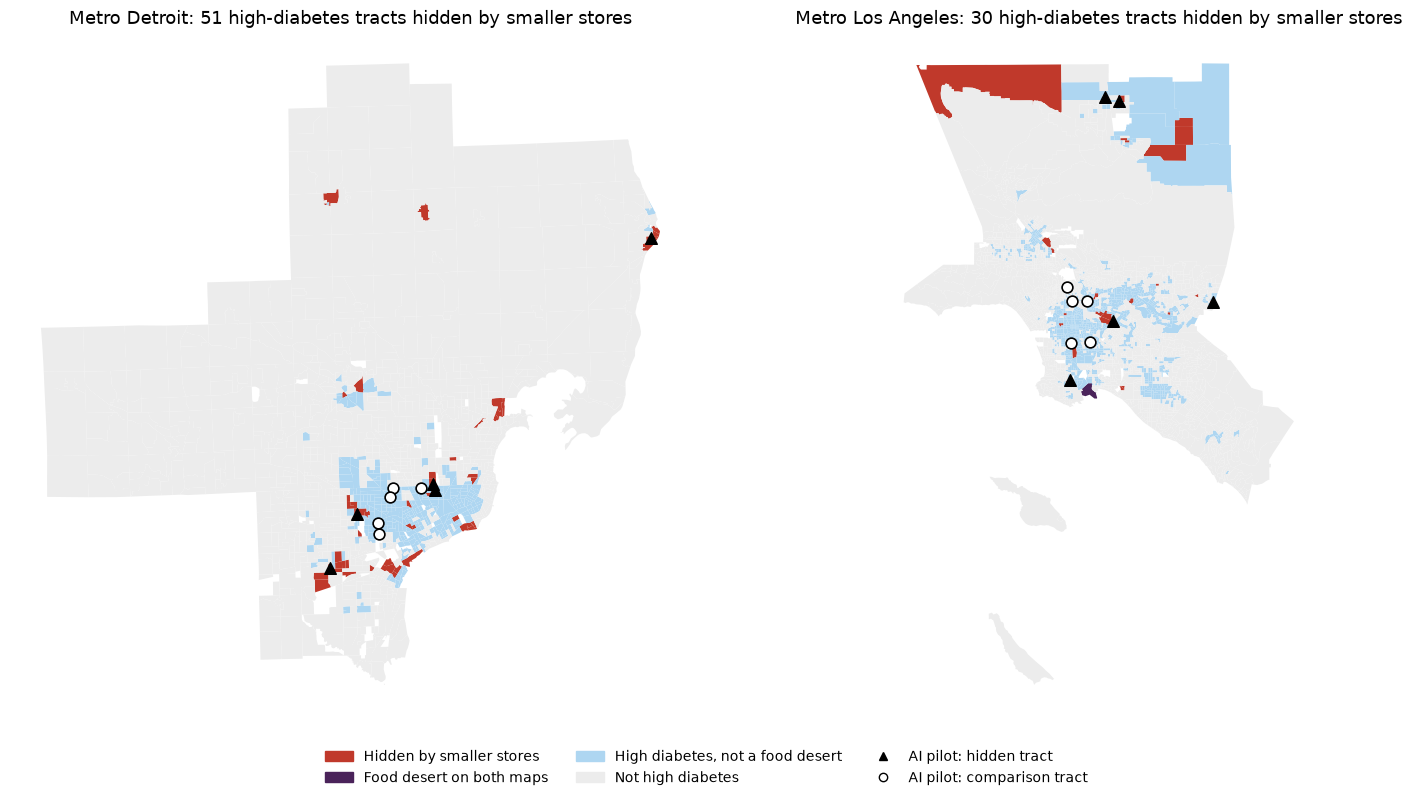

In [16]:
pilot = pd.read_csv(CLEAN/'ai_pilot_tracts.csv', dtype={'GEOID':str})
pts = mp2[mp2.GEOID.isin(pilot.GEOID)].merge(pilot[['GEOID','grp']], on='GEOID')
pts = pts.assign(geometry=pts.geometry.representative_point())
print(pts.groupby(['metro','grp']).size())          # CHECK: 5 per group per metro
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, name in zip(axes, ['Metro Detroit','Metro Los Angeles']):
    d = mp2[mp2.metro==name].assign(cat=lambda x: cat2(x))
    for k, colr in col2.items():
        sub = d[d['cat']==k]
        if len(sub): sub.plot(ax=ax, color=colr, linewidth=0)
    p = pts[pts.metro==name]
    p[p.grp=='Hidden'].plot(ax=ax, marker='^', color='black', markersize=70)
    p[p.grp=='Comparison'].plot(ax=ax, marker='o', color='white', edgecolor='black', markersize=60, linewidth=1.2)
    n = int((d['cat']=='Hidden by smaller stores').sum())
    ax.set_title(f"{name}: {n} high-diabetes tracts hidden by smaller stores", fontsize=13); ax.set_axis_off()
h = [plt.Rectangle((0,0),1,1,color=v) for v in col2.values()]
h += [plt.Line2D([],[],marker='^',color='black',ls=''), plt.Line2D([],[],marker='o',mfc='white',mec='black',ls='')]
fig.legend(h, list(col2.keys())+['AI pilot: hidden tract','AI pilot: comparison tract'], loc='lower center', ncol=3, frameon=False)
plt.tight_layout(rect=[0,0.08,1,1]); plt.savefig(FIG/'fig2_hidden_food_deserts_with_pilot.png', dpi=200); plt.show()